# 03 – Chia tập Train/Test theo chuỗi thời gian

**Mục tiêu:** Chia dữ liệu đầu vào `X` và biến mục tiêu `y` thành tập huấn luyện (Train) và tập kiểm tra (Test) theo đúng thứ tự thời gian.

Notebook sử dụng kết quả từ Bước 2 và Bước 3:
- `X_lag_p24.csv`: 24 đặc trưng trễ `lag_1` đến `lag_24`.
- `y_AEP_MW.csv`: giá trị mục tiêu `AEP_MW`.
- Tỷ lệ chia: **80% Train – 20% Test**.
- Không xáo trộn dữ liệu (`shuffle=False`); 80% quan sát cũ hơn dùng để huấn luyện, 20% quan sát mới hơn ở cuối chuỗi dùng để kiểm tra.

**Lưu ý:** Đây là cách đánh giá theo thời gian. Các dòng Test vẫn có thể sử dụng những giá trị lịch sử thực tế trước thời điểm dự đoán làm lag, phù hợp với kịch bản dự báo từng thời điểm (one-step-ahead).

## 1. Import thư viện và xác định đường dẫn dữ liệu

In [8]:
from pathlib import Path
import pandas as pd
import numpy as np

# Tìm thư mục chứa dữ liệu đã xử lý khi chạy từ thư mục gốc repo hoặc notebooks/
candidate_dirs = [
    Path("data/processed"),
    Path("../data/processed")
]
data_dir = next((p for p in candidate_dirs if p.exists()), None)

if data_dir is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục data/processed. "
        "Hãy chạy notebook 02_lag_features_X_y.ipynb trước."
    )

x_path = data_dir / "X_lag_p24.csv"
y_path = data_dir / "y_AEP_MW.csv"

if not x_path.exists() or not y_path.exists():
    raise FileNotFoundError(
        "Thiếu X_lag_p24.csv hoặc y_AEP_MW.csv trong data/processed. "
        "Hãy chạy hoàn tất Bước 2 và Bước 3."
    )

print("Thư mục dữ liệu:", data_dir.resolve())
print("Tệp X:", x_path.name)
print("Tệp y:", y_path.name)

Thư mục dữ liệu: C:\03_time\xgboost-time-series-lab2\DATA\processed
Tệp X: X_lag_p24.csv
Tệp y: y_AEP_MW.csv


## 2. Đọc dữ liệu X và y

In [9]:
# Đọc cột Datetime làm chỉ mục thời gian
X = pd.read_csv(x_path, index_col="Datetime", parse_dates=True)
y_df = pd.read_csv(y_path, index_col="Datetime", parse_dates=True)

# Chuyển y từ DataFrame một cột thành Series
if "AEP_MW" not in y_df.columns:
    raise KeyError("Không tìm thấy cột AEP_MW trong tệp y_AEP_MW.csv")
y = y_df["AEP_MW"]

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)
print("Thời gian bắt đầu:", X.index.min())
print("Thời gian kết thúc:", X.index.max())

display(X.head())
display(y.head())

Kích thước X: (121245, 24)
Kích thước y: (121245,)
Thời gian bắt đầu: 2004-10-02 01:00:00
Thời gian kết thúc: 2018-08-03 00:00:00


,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,...,lag_15,lag_16,lag_17,lag_18,lag_19,lag_20,lag_21,lag_22,lag_23,lag_24
Datetime,,,,,,,,,,,,,,,,,,,,,
2004-10-02 01:00:00,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,15739.0,15739.0,...,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0,11935.0,12379.0
2004-10-02 02:00:00,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,15739.0,...,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0,11935.0
2004-10-02 03:00:00,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,...,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0
2004-10-02 04:00:00,11352.0,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,...,15404.0,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0
2004-10-02 05:00:00,11177.0,11352.0,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,...,15655.0,15404.0,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0


Datetime
2004-10-02 01:00:00    12260.0
2004-10-02 02:00:00    11672.0
2004-10-02 03:00:00    11352.0
2004-10-02 04:00:00    11177.0
2004-10-02 05:00:00    11142.0
Name: AEP_MW, dtype: float64

## 3. Kiểm tra dữ liệu trước khi chia

In [10]:
# Kiểm tra số lượng mẫu, thứ tự thời gian và sự tương ứng giữa X với y
print("X và y có cùng số mẫu:", len(X) == len(y))
print("X và y có cùng chỉ mục:", X.index.equals(y.index))
print("Index X tăng dần:", X.index.is_monotonic_increasing)
print("Timestamp trùng trong X:", X.index.has_duplicates)
print("Missing values trong X:", int(X.isna().sum().sum()))
print("Missing values trong y:", int(y.isna().sum()))

# Dừng chương trình nếu dữ liệu không đáp ứng điều kiện
assert len(X) == len(y), "X và y không có cùng số lượng mẫu!"
assert X.index.equals(y.index), "Chỉ mục thời gian của X và y không khớp!"
assert X.index.is_monotonic_increasing, "Dữ liệu chưa được sắp xếp tăng dần theo thời gian!"
assert not X.index.has_duplicates, "Chỉ mục thời gian đang có timestamp trùng!"
assert X.isna().sum().sum() == 0, "X còn giá trị thiếu!"
assert y.isna().sum() == 0, "y còn giá trị thiếu!"

print("\nDữ liệu hợp lệ, sẵn sàng chia Train/Test.")

X và y có cùng số mẫu: True
X và y có cùng chỉ mục: True
Index X tăng dần: True
Timestamp trùng trong X: False
Missing values trong X: 0
Missing values trong y: 0

Dữ liệu hợp lệ, sẵn sàng chia Train/Test.


## 4. Chia Train/Test theo thứ tự thời gian

Sử dụng tỷ lệ 80% cho Train và 20% cho Test. Không sử dụng `train_test_split` với cơ chế xáo trộn ngẫu nhiên. Thay vào đó, lấy phần đầu chuỗi làm Train và phần cuối chuỗi làm Test.

In [11]:
# Khai báo tỷ lệ dữ liệu dùng để huấn luyện
train_ratio = 0.80

# Xác định vị trí chia theo số lượng mẫu
split_idx = int(len(X) * train_ratio)

# Chia dữ liệu theo vị trí, giữ nguyên thứ tự thời gian
X_train = X.iloc[:split_idx].copy()
X_test = X.iloc[split_idx:].copy()

y_train = y.iloc[:split_idx].copy()
y_test = y.iloc[split_idx:].copy()

print("Vị trí chia:", split_idx)
print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test :", X_test.shape)
print("Kích thước y_train:", y_train.shape)
print("Kích thước y_test :", y_test.shape)

Vị trí chia: 96996
Kích thước X_train: (96996, 24)
Kích thước X_test : (24249, 24)
Kích thước y_train: (96996,)
Kích thước y_test : (24249,)


## 5. Kiểm tra kết quả chia tập

In [12]:
# Kiểm tra số lượng mẫu sau khi chia
total_samples = len(X_train) + len(X_test)

print(f"Tổng số mẫu ban đầu: {len(X)}")
print(f"Số mẫu Train: {len(X_train)} ({len(X_train) / len(X) * 100:.2f}%)")
print(f"Số mẫu Test : {len(X_test)} ({len(X_test) / len(X) * 100:.2f}%)")
print(f"Tổng Train + Test: {total_samples}")

print("\nKhoảng thời gian của từng tập:")
print("Train:", X_train.index.min(), "->", X_train.index.max())
print("Test :", X_test.index.min(), "->", X_test.index.max())

# Đảm bảo Train nằm trước Test và không có giao nhau về chỉ mục
assert len(X_train) > 0 and len(X_test) > 0, "Train hoặc Test đang rỗng!"
assert X_train.index.max() < X_test.index.min(), "Có nguy cơ trộn lẫn thứ tự thời gian!"
assert X_train.index.intersection(X_test.index).empty, "Train và Test bị trùng timestamp!"
assert X_train.index.equals(y_train.index), "Index X_train và y_train không khớp!"
assert X_test.index.equals(y_test.index), "Index X_test và y_test không khớp!"
assert total_samples == len(X), "Số mẫu sau chia không bằng dữ liệu ban đầu!"

print("\nKết luận: Chia Train/Test theo thời gian thành công.")

Tổng số mẫu ban đầu: 121245
Số mẫu Train: 96996 (80.00%)
Số mẫu Test : 24249 (20.00%)
Tổng Train + Test: 121245

Khoảng thời gian của từng tập:
Train: 2004-10-02 01:00:00 -> 2015-10-27 12:00:00
Test : 2015-10-27 13:00:00 -> 2018-08-03 00:00:00

Kết luận: Chia Train/Test theo thời gian thành công.


## 6. Trực quan hóa mốc chia Train/Test

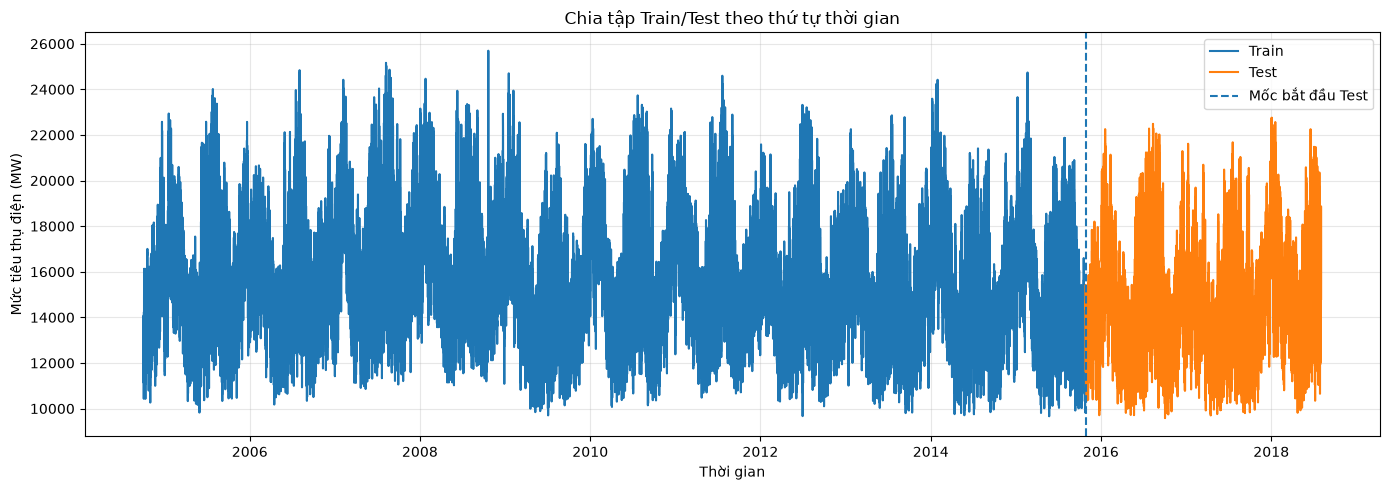

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(y_train.index, y_train, label="Train")
plt.plot(y_test.index, y_test, label="Test")
plt.axvline(X_test.index[0], linestyle="--", label="Mốc bắt đầu Test")
plt.title("Chia tập Train/Test theo thứ tự thời gian")
plt.xlabel("Thời gian")
plt.ylabel("Mức tiêu thụ điện (MW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Lưu dữ liệu Train/Test

In [14]:
# Tạo thư mục đầu ra; hỗ trợ chạy từ thư mục gốc repo hoặc notebooks/
if Path("data").exists():
    output_dir = Path("data/processed")
else:
    output_dir = Path("../data/processed")

output_dir.mkdir(parents=True, exist_ok=True)

# Lưu riêng từng tập để sử dụng ở Bước 5 – huấn luyện mô hình
X_train.to_csv(output_dir / "X_train.csv", index_label="Datetime")
X_test.to_csv(output_dir / "X_test.csv", index_label="Datetime")
y_train.to_frame(name="AEP_MW").to_csv(output_dir / "y_train.csv", index_label="Datetime")
y_test.to_frame(name="AEP_MW").to_csv(output_dir / "y_test.csv", index_label="Datetime")

print("Đã lưu các tệp tại:", output_dir.resolve())
for filename in ["X_train.csv", "X_test.csv", "y_train.csv", "y_test.csv"]:
    print("-", filename)

Đã lưu các tệp tại: C:\03_time\xgboost-time-series-lab2\DATA\processed
- X_train.csv
- X_test.csv
- y_train.csv
- y_test.csv


## 8. Kết luận

Dữ liệu được chia thành hai tập theo đúng trình tự thời gian với tỷ lệ 80% Train và 20% Test. Tập Train gồm các quan sát ở giai đoạn trước, còn tập Test gồm các quan sát mới hơn ở cuối chuỗi. Quá trình chia không xáo trộn dữ liệu, nhờ đó hạn chế nguy cơ rò rỉ thông tin từ tương lai vào quá trình huấn luyện.

Các tập `X_train`, `X_test`, `y_train` và `y_test` đã được lưu trong `data/processed/`, sẵn sàng sử dụng cho Bước 5 – huấn luyện mô hình XGBoost Regressor.

**Lưu ý:** Việc chia 80/20 là cấu hình thực nghiệm ban đầu theo yêu cầu bài tập; có thể cân nhắc các tỷ lệ khác trong quá trình đánh giá mô hình.

In [15]:
# Điều chỉnh bố cục biểu đồ
plt.tight_layout()

# Tạo thư mục lưu hình
from pathlib import Path

figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

# Lưu biểu đồ với chất lượng cao
figure_path = figure_dir / "train_test_split.png"

plt.savefig(figure_path, dpi=300, bbox_inches="tight")

# Hiển thị biểu đồ
plt.show()

print("Đã lưu biểu đồ tại:", figure_path.resolve())

<Figure size 640x480 with 0 Axes>

Đã lưu biểu đồ tại: C:\03_time\xgboost-time-series-lab2\reports\figures\train_test_split.png
